#LSA

[Latent Semantic Analysis](https://asistdl.onlinelibrary.wiley.com/doi/epdf/10.1002/%28SICI%291097-4571%28199009%2941%3A6%3C391%3A%3AAID-ASI1%3E3.0.CO%3B2-9) (LSA), published in JASIST in 1990, is a natural language processing (NLP) technique used to analyze relationships between a set of documents and the terms they contain. LSA applies a mathematical technique called Singular Value Decomposition (SVD) to reduce the dimensions of the document-term matrix.

## The intuition of SVD
Singular Value Decomposition is a way to *decompose* a matrix into constituent matrices. This means we break a single matrix down into several matrices which, when multiplied together, create the original matrix. To visualise this, it is useful to think of matrices as being transforms on vectors: we take a matrix, put a vector in, and get a changed vector out. Instead of just using one matrix to do this, we can break down the process into several steps, which can tell us useful information about our original matrix. In particular, we can model an original matrix as a matrix of columns, each of which has a certain level of "importance" in modelling the original matrix, and a set way in which to mix them to reconstitute the original matrix. Though this sounds very abstract, it is a useful way to think about SVD: we are breaking down a matrix into its constituent parts along with how important those parts are to the original matrix. For further reading, have a look at Chapter 12 of "Machine Learning a Probabilistic Approach", or watch this (very useful) youtube video https://www.youtube.com/watch?v=nbBvuuNVfco


## The maths in depth

SVD generalizes the eigenvalue decomposition, since the latter only makes sense for $n\times n$ matrices, SVD always exists for matrices of any shape $m\times n$. Let's call $M\in\mathbf{C}^{m\times n}$, meaning all it's elements are complex numbers, it can be proven that there is always a unique way to rewrite it into the following form

$$
M = U\Sigma V^*
$$

where $U\in\mathbf{C}^{m\times m}$, $V\in\mathbf{C}^{n\times n}$ and $\Sigma\in\mathbf{R}^{m\times n}$, the last one being a diagonal matrix. It essentially captures a notion of how large the matrix is, and how much the matrix is going to stretch a vector in different directions. The non-zero elements of $\Sigma$ (non-zero singular values) can be calculated as the square roots of the non-zero eigenvalues of $M^*M$ or $MM^*$. Remember, for real matrices $M^*=M^T$, however for complex matrices there's an additional conjugation to perform.

Since it is a very convenient mathematical tool, it can be found in many places, such as in the LSA, or in [AdaLoRA](https://arxiv.org/pdf/2303.10512), the technique we saw in the previous series of notebooks for finetuning. Also keep in mind that SVD produces the full set of singular values and vectors, while truncated SVD produces only a subset of the full set. This makes truncated SVD faster and more memory-efficient than SVD, especially with large matrices.

## What does this have to do with topic modelling?

As we said earlier, SVD gives an impression of how *important* parts of the matrix are. Now, let's make the example concrete by imagining the matrix in question as a word-document matrix (either count, or TF-IDF). If we perform SVD, we end up with $$M = U \Sigma V^*$$ as described above. The $\Sigma$ diagonal matrix is organised heirarchically: $\sigma_1 < \sigma_2 < \sigma_3 ...$. These values correspond with the columns in $U$ (these are the topics) and the rows in $v$ (these are how we *mix* the topics). Because $\Sigma$ is heirarchical, we can drop the unimportant parts (the unimportant topics and mixtures of topics). This forces our model to generalise and learn how to represent the topics in a lower-dimensional way than our original matrix!

In [3]:
import numpy as np

M = np.random.randn(10, 10)

# Step 1: Compute SVD using numpy.linalg.svd
U, S, Vt = np.linalg.svd(M, full_matrices=False)

# Step 2: Step by step computation of SVD
# Compute M^T M and MM^T
MMT = np.dot(M, M.T)  # Document-document covariance
# EXERCISE: multiply with M.T on the left, to see if the SVD is the same or not
MTM = np.dot(M.T, M)

# Eigen decomposition for explicit computation
eig_vals_MMT, U_explicit = np.linalg.eigh(MMT)  # Eigenvalues and eigenvectors
eig_vals_MTM, V_explicit = np.linalg.eigh(MTM)

# Sort eigenvalues and eigenvectors in descending order
sorted_indices_MMT = np.argsort(eig_vals_MMT)[::-1]
sorted_indices_MTM = np.argsort(eig_vals_MTM)[::-1]

U_explicit = U_explicit[:, sorted_indices_MMT]  # Left singular vectors
V_explicit = V_explicit[:, sorted_indices_MTM]  # Right singular vectors

# EXERCISE: take the sqrt of the eigenvalues after sorting them
S_explicit_MMT = np.sqrt(eig_vals_MTM[sorted_indices_MMT])
S_explicit_MTM = np.sqrt(eig_vals_MTM[sorted_indices_MTM])  # Singular values


# Step 4: Normalize U and V explicitly to match SVD output (optional)
U_explicit /= np.linalg.norm(U_explicit, axis=0)
V_explicit /= np.linalg.norm(V_explicit, axis=0)

print(S)
print(S_explicit_MMT)
print(S_explicit_MTM)

[5.14583341 4.61774962 3.68179634 3.1954564  2.95804708 2.86506749
 2.2062913  1.37374373 0.83911877 0.31397113]
[5.14583341 4.61774962 3.68179634 3.1954564  2.95804708 2.86506749
 2.2062913  1.37374373 0.83911877 0.31397113]
[5.14583341 4.61774962 3.68179634 3.1954564  2.95804708 2.86506749
 2.2062913  1.37374373 0.83911877 0.31397113]


You see? we got the same results with three different methods.

## From scratch

Now let's see in detail the parts of LSA.

In [4]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# Sample document corpus
documents = [
    "The cat sat on the mat.",
    "The dog barked at the mailman.",
    "Cats and dogs are friends.",
    "The mailman delivered the mail."
]

# Step 1: Vectorize the documents using TF-IDF
vectorizer = TfidfVectorizer(stop_words='english')
docterm_matrix = vectorizer.fit_transform(documents).toarray()  # Convert to dense array for explicit SVD

# Step 2: Compute SVD explicitly
U, S, Vt = np.linalg.svd(docterm_matrix, full_matrices=False)

# Shapes of the matrices:
# U: (n_docs, n_topics)
# S: (n_topics,)
# Vt: (n_topics, n_terms)

# Step 3: Dimensionality Reduction
# To reduce dimensions, we can keep only the top `n_topics` singular values and corresponding vectors.
n_topics = 5  # Number of topics to extract
U_reduced = U[:, :n_topics]  # Reduced document-topic matrix
S_reduced = S[:n_topics]  # Diagonal matrix of top singular values
Vt_reduced = Vt[:n_topics, :]  # Reduced topic-term matrix

# Step 4: Interpret topics
terms = vectorizer.get_feature_names_out()
topics = []
for i, component in enumerate(Vt_reduced):  # Rows in Vt correspond to topics
    terms_in_topic = [(terms[idx], weight) for idx, weight in enumerate(component)]
    sorted_terms = sorted(terms_in_topic, key=lambda x: -x[1])[:10]  # Top 10 terms per topic
    topics.append(sorted_terms)

# Step 5: Display results
print("Original Term-Doc (TF-IDF) Matrix:")
print(docterm_matrix)

print("\nAll Singular Values:")
print(S)

print("\nTop Singular Values:")
print(S_reduced)

print("\nDocument-Topic Matrix (U reduced):")
print(U_reduced)

print("\nTopic-Term Matrix (Vt reduced):")
print(Vt_reduced)

print("\nTopics:")
for i, topic in enumerate(topics):
    print(f"Topic {i + 1}:")
    for term, weight in topic:
        print(f"  {term}: {weight:.4f}")


Original Term-Doc (TF-IDF) Matrix:
[[0.         0.57735027 0.         0.         0.         0.
  0.         0.         0.         0.57735027 0.57735027]
 [0.61761437 0.         0.         0.         0.61761437 0.
  0.         0.         0.48693426 0.         0.        ]
 [0.         0.         0.57735027 0.         0.         0.57735027
  0.57735027 0.         0.         0.         0.        ]
 [0.         0.         0.         0.61761437 0.         0.
  0.         0.61761437 0.48693426 0.         0.        ]]

All Singular Values:
[1.11225221 1.         1.         0.87343862]

Top Singular Values:
[1.11225221 1.         1.         0.87343862]

Document-Topic Matrix (U reduced):
[[ 0.00000000e+00  1.00000000e+00  0.00000000e+00  0.00000000e+00]
 [-7.07106781e-01  0.00000000e+00 -5.12275937e-17  7.07106781e-01]
 [ 0.00000000e+00  0.00000000e+00 -1.00000000e+00  0.00000000e+00]
 [-7.07106781e-01  0.00000000e+00  2.16054484e-16 -7.07106781e-01]]

Topic-Term Matrix (Vt reduced):
[[-3.92644

## On sklearn

If we wanna keep the code clean and we understand sufficiently what is going on behind the scenes, we can use wrappers as sklearn.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

# Sample document corpus
documents = [
    "The cat sat on the mat.",
    "The dog barked at the mailman.",
    "Cats and dogs are friends.",
    "The mailman delivered the mail."
]

# Step 1: Vectorize the documents using TF-IDF
vectorizer = TfidfVectorizer(stop_words='english')
docterm_matrix = vectorizer.fit_transform(documents)  # Shape: (n_docs, n_terms)

# Step 2: Apply Truncated SVD (explicit fit_transform)
n_topics = 4  # Number of topics to extract
svd = TruncatedSVD(n_components=n_topics, random_state=0)
document_topic_matrix = svd.fit_transform(docterm_matrix)

# Step 3: Extract topics
terms = vectorizer.get_feature_names_out()
topics = []
for i, component in enumerate(svd.components_):  # Components are the topic-term matrices
    terms_in_topic = [(terms[idx], weight) for idx, weight in enumerate(component)]
    sorted_terms = sorted(terms_in_topic, key=lambda x: -x[1])[:10]  # Top 10 terms per topic
    topics.append(sorted_terms)

# Step 4: Display the topics
print("Document-Topic Matrix:")
print(document_topic_matrix)  # Each row corresponds to a document, columns to topics

print("\nTopics:")
for i, topic in enumerate(topics):
    print(f"Topic {i + 1}:")
    for term, weight in topic:
        print(f"  {term}: {weight:.4f}")


Document-Topic Matrix:
[[-1.26970786e-16  1.00000000e+00  2.25451670e-17  1.60409292e-17]
 [ 7.86481080e-01 -7.45505590e-17  2.14378173e-16 -6.17614371e-01]
 [-1.97551318e-16  1.96813565e-17  1.00000000e+00  5.06091182e-17]
 [ 7.86481080e-01  1.77151652e-17  1.40080843e-16  6.17614371e-01]]

Topics:
Topic 1:
  mailman: 0.6191
  delivered: 0.3926
  mail: 0.3926
  barked: 0.3926
  dog: 0.3926
  mat: -0.0000
  sat: -0.0000
  cat: -0.0000
  cats: -0.0000
  dogs: -0.0000
Topic 2:
  mat: 0.5774
  sat: 0.5774
  cat: 0.5774
  mail: 0.0000
  cats: 0.0000
  dog: 0.0000
  dogs: -0.0000
  friends: -0.0000
  delivered: -0.0000
  mailman: -0.0000
Topic 3:
  dogs: 0.5774
  friends: 0.5774
  cats: 0.5774
  barked: 0.0000
  cat: 0.0000
  delivered: 0.0000
  mailman: 0.0000
  dog: 0.0000
  mail: 0.0000
  mat: -0.0000
Topic 4:
  mail: 0.5000
  delivered: 0.5000
  cats: 0.0000
  cat: 0.0000
  dogs: 0.0000
  friends: 0.0000
  mat: 0.0000
  sat: 0.0000
  mailman: -0.0000
  dog: -0.5000


#pLSA

[Probabilistic Latent Semantic Analysis](https://arxiv.org/pdf/1301.6705) (pLSA), published in SIGIR in 1999, is based on a mixture decomposition derived from a latent model. This results in an approach with solid foundation in statistics, compared to standard LSA which stems from linear algebra.

##The maths: Graphical Model

In pLSA method chooses the simplifying assumption that the probabilistic relationship between documents and words behaves as follows:

$$
p(w,d) = \sum_zp(d|z)p(w|z)p(z)
$$

where $w,d$ stand for word and document, while $z$ stands for topic. Remember that in general, following probability rules, we can only say that

$$
p(w,d) = \sum_zp(d,w|z)p(z)
$$

so pLSA is proposing as an assumption that when the topic is known, words and documents are statistically independent: $p(d,w|z)=p(d|z)p(w|z)$.
Don't forget also that you can use Bayes rule to do things like

$$
p(z|d)p(d) = p(d|z)p(z)
$$


What they define is what is called a Graphical Model in Bayesian Statistics, which defines a set of assumptions on how elements influence and condition each other probabilistically. You can represent such a model in what is called [plate notation](https://en.wikipedia.org/wiki/Plate_notation), below we see the example of the plate notation to describe the pLSA:

<div >
<center>
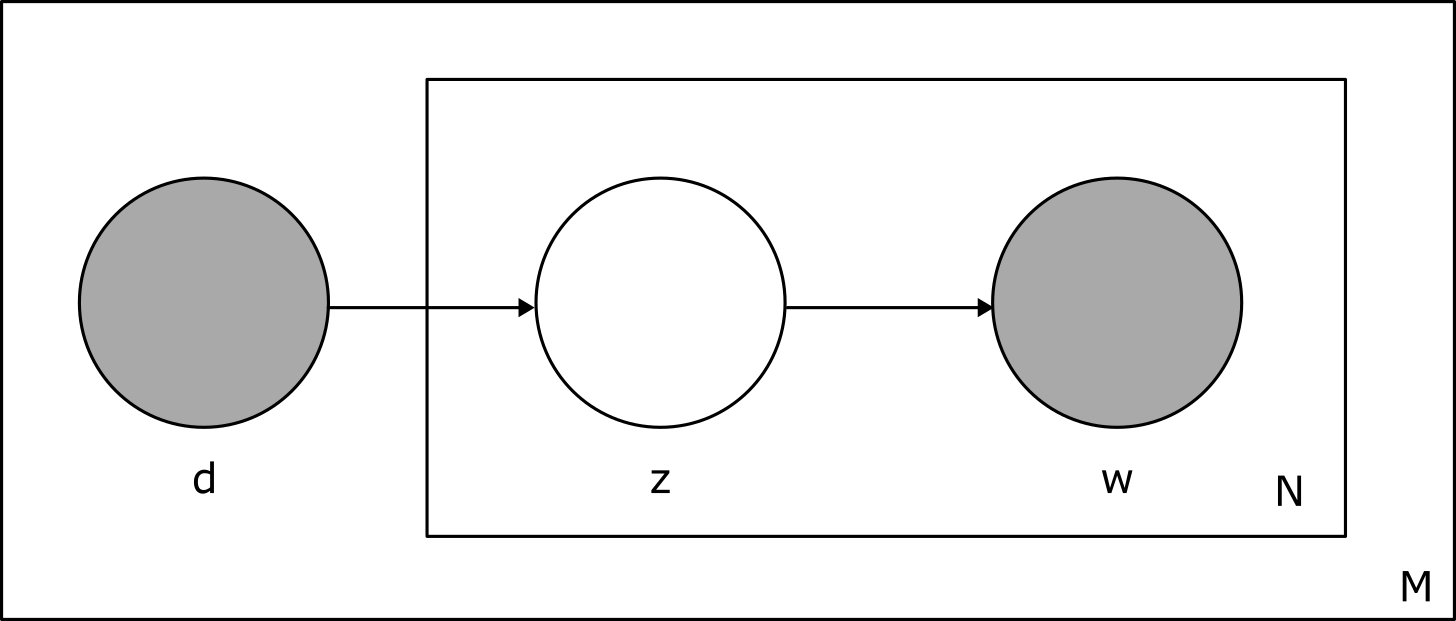
</center>
</div>


This picture defines a factorization of the joint distribution of all observed and hidden random variables.

Here $d$ is the document index variable, $z$ a word's topic drawn from the document's topic distribution, $p(z|d)$, and $w$ is a word drawn from the word distribution of this word's topic, $p(w|z)$. The $d$ and $w$ are observable variables, available as data, and that's why their circles are filled in gray, while the topic $z$ is a latent variable.

The $M$ in the corner of the plate indicates that the variables inside are repeated $M$ times, once for each document. The inner plate represents the variables associated with each of the $N_i$ words in document $i$:
$z_{i,j}$ is the topic distribution for the $j$-th word in document $i$, and
 $w_{ij}$ is the actual word used.

## Optimization: Expectation-Maximization

Now you want to learn the $p(z|d)$, $p(w|z)$ and $p(d)$ that are closest to the data. There are many ways to do that, the most common nowadays would be through gradient descent for Deep Neural Networks. We are going to see the use of another iterative optimization algorithm called Expectation-Maximization (EM).

The Expectation-Maximization (EM) algorithm aims to find the maximum likelihood estimate (MLE) of the marginal likelihood by iteratively alternating between two steps:

1. **Expectation Step (E step):** Compute the expected value of the log-likelihood function,
$Q(\theta|\theta_t)$, given the current parameter estimates $\theta_t$. This expectation is taken over the conditional distribution of the latent variables
$Z$, conditioned on the observed data $X$ and the current parameter estimates:

$$
Q(\theta|\theta_t) = \textbf{E}_{Z\sim p (\cdot| X, \theta_t)}[\log p(X,Z|\theta)]
$$

2. **Maximization Step (M step):** Update the parameter estimates by maximizing
$Q(\theta|\theta_t)$ with respect to $\theta$:

$$
\theta_{t+1} = \arg \max_\theta Q(\theta|\theta_t)
$$

These steps are repeated iteratively until convergence, leading to parameter estimates that maximize the likelihood function.


If we optimize iteratively, we have to choose also initial values for those probabilities, an initialization. The original paper doesn't specify any, so we can go with a random initialization of each since the probabilities will be normalized in the training loop.

## From scratch

Before getting used to use the convenience functions that hide all the tricks, let's have a quick look at the training loop.

In [10]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

# Sample document corpus
documents = [
    "The cat sat on the mat.",
    "The dog barked at the mailman.",
    "Cats and dogs are friends.",
    "The mailman delivered the mail."
]

# Step 1: Vectorize the documents using CountVectorizer (Bag-of-Words)
vectorizer = CountVectorizer(stop_words='english')
word_count_matrix = vectorizer.fit_transform(documents).toarray()  # Shape: (n_docs, n_terms)
n_docs, n_terms = word_count_matrix.shape
terms = vectorizer.get_feature_names_out()

# Step 2: Initialize pLSA parameters
n_topics = 2  # Number of topics
# P_w_z = np.random.dirichlet(alpha=np.ones(n_terms), size=n_topics)  # Word distributions per topic
# P_z_d = np.random.dirichlet(alpha=np.ones(n_topics), size=n_docs)  # Topic distributions per document

# P_w_z = np.ones((n_topics, n_terms))/n_terms  # Word distributions per topic
# P_z_d = np.ones((n_docs, n_topics))/n_topics  # Topic distributions per document

P_w_z = np.random.uniform(size=(n_topics, n_terms))  # Word distributions per topic
P_z_d = np.random.uniform(size=(n_docs, n_topics))  # Topic distributions per document

P_d = word_count_matrix.sum(axis=1) / word_count_matrix.sum()  # Document probabilities (optional)


# Step 3: EM Algorithm for pLSA
max_iter = 1000
epsilon = 1e-4
for iteration in range(max_iter):
    # E-step: Compute posterior probabilities P(z | d, w)
    P_z_dw = np.zeros((n_docs, n_terms, n_topics))
    for d in range(n_docs):
        for w in range(n_terms):
            prob_z = P_w_z[:, w] * P_z_d[d, :]
            P_z_dw[d, w, :] = prob_z / prob_z.sum() if prob_z.sum() > 0 else 0

    # M-step: Update P(w | z) and P(z | d)
    P_w_z = np.zeros_like(P_w_z)
    P_z_d = np.zeros_like(P_z_d)
    for z in range(n_topics):
        for w in range(n_terms):
            P_w_z[z, w] = (word_count_matrix[:, w] * P_z_dw[:, w, z]).sum()
        P_w_z[z, :] /= P_w_z[z, :].sum()

        for d in range(n_docs):
            P_z_d[d, z] = (word_count_matrix[d, :] * P_z_dw[d, :, z]).sum()
    P_z_d /= P_z_d.sum(axis=1, keepdims=True)

    # Convergence check
    if iteration > 1 and np.abs(P_w_z - P_w_z_prev).sum() < epsilon:
        break
    P_w_z_prev = P_w_z.copy()

# Step 4: Display results
print("Word distributions per topic (P(w | z)):")
for z in range(n_topics):
    print(f"Topic {z + 1}:")
    for w_idx in np.argsort(P_w_z[z, :])[::-1][:10]:  # Top 10 words per topic
        print(f"  {terms[w_idx]}: {P_w_z[z, w_idx]:.4f}")

print("\nTopic distributions per document (P(z | d)):")
for d in range(n_docs):
    print(f"Document {d + 1}: {P_z_d[d, :]}")


Word distributions per topic (P(w | z)):
Topic 1:
  sat: 0.1667
  mat: 0.1667
  cat: 0.1667
  cats: 0.1667
  friends: 0.1667
  dogs: 0.1667
  dog: 0.0000
  barked: 0.0000
  mailman: 0.0000
  mail: 0.0000
Topic 2:
  mailman: 0.3333
  dog: 0.1667
  mail: 0.1667
  barked: 0.1667
  delivered: 0.1667
  dogs: 0.0000
  friends: 0.0000
  cats: 0.0000
  sat: 0.0000
  cat: 0.0000

Topic distributions per document (P(z | d)):
Document 1: [1.00000000e+000 2.44374046e-194]
Document 2: [2.67832167e-41 1.00000000e+00]
Document 3: [1.00000000e+00 3.24749965e-11]
Document 4: [7.82323422e-56 1.00000000e+00]


EXERCISE: change initializations. What happens when all matrices are initialized with a uniform distribution?

## On sklearn

In the ```sklearn``` library pLSA is equivalent to Non-negative Matrix Factorization with Kullback-Leibler divergence as an objective function ([here](https://scikit-learn.org/1.5/auto_examples/applications/plot_topics_extraction_with_nmf_lda.html#sphx-glr-auto-examples-applications-plot-topics-extraction-with-nmf-lda-py)):

In [12]:
from time import time
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD


# Sample document corpus
documents = [
    "The cat sat on the mat.",
    "The dog barked at the mailman.",
    "Cats and dogs are friends.",
    "The mailman delivered the mail."
]

# Use tf-idf features for NMF.
print("Extracting tf-idf features for NMF...")
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf = tfidf_vectorizer.fit_transform(documents)
n_components = 4
# Fit the NMF model
print(
    "Fitting the NMF model (generalized Kullback-Leibler "
    "divergence) with tf-idf features",
)
t0 = time()
nmf = NMF(
    n_components=n_components,
    random_state=42,
    beta_loss="kullback-leibler",
    solver="mu",
    init = "nndsvda"
).fit(tfidf)
print("done in %0.3fs." % (time() - t0))


# Step 3: Extract topics
terms = vectorizer.get_feature_names_out()
topics = []
for i, component in enumerate(nmf.components_):  # Components are the topic-term matrices
    terms_in_topic = [(terms[idx], weight) for idx, weight in enumerate(component)]
    sorted_terms = sorted(terms_in_topic, key=lambda x: -x[1])[:10]  # Top 10 terms per topic
    topics.append(sorted_terms)

print("\nTopics:")
for i, topic in enumerate(topics):
    print(f"Topic {i + 1}:")
    for term, weight in topic:
        print(f"  {term}: {weight:.4f}")


Extracting tf-idf features for NMF...
Fitting the NMF model (generalized Kullback-Leibler divergence) with tf-idf features
done in 0.072s.

Topics:
Topic 1:
  barked: 0.9737
  dog: 0.9737
  mailman: 0.7677
  cat: 0.0000
  cats: 0.0000
  delivered: 0.0000
  dogs: 0.0000
  friends: 0.0000
  mail: 0.0000
  mat: 0.0000
Topic 2:
  mat: 0.9874
  sat: 0.9874
  cat: 0.9874
  barked: 0.0000
  cats: 0.0000
  delivered: 0.0000
  dog: 0.0000
  dogs: 0.0000
  friends: 0.0000
  mail: 0.0000
Topic 3:
  cats: 0.9874
  dogs: 0.9874
  friends: 0.9874
  barked: 0.0000
  cat: 0.0000
  delivered: 0.0000
  dog: 0.0000
  mail: 0.0000
  mailman: 0.0000
  mat: 0.0000
Topic 4:
  delivered: 1.1162
  mail: 1.1162
  mailman: 0.8800
  barked: 0.0000
  cat: 0.0000
  cats: 0.0000
  dog: 0.0000
  dogs: 0.0000
  friends: 0.0000
  mat: 0.0000


#LDA

[Latent Dirichlet Allocation](https://www.jmlr.org/papers/volume3/blei03a/blei03a.pdf) (LDA), published at JMLR in 2003, is a Bayesian network and, therefore, a generative statistical model, for modeling automatically extracted topics in textual corpora.

While pLSA is a useful step toward probabilistic modeling of text, it is incomplete in that it provides no probabilistic model at the level of documents. In pLSA, each document is represented as a list of numbers (the mixing proportions for topics), and there is no generative
probabilistic model for these numbers. This leads to several problems:

1. the number of parameters in the model grows linearly with the size of the corpus, which leads to serious problems with overfitting;
2.  it is not clear how to assign probability to a document outside of the training set.

## The maths: Generative Models

Now the model that describes the LDA is a bit more sofisticated

$$
p(\mathbf{w},\mathbf{z},\theta,\phi|\alpha,\beta) = p(\mathbf{w}|\phi, \mathbf{z})p(\mathbf{z}|\theta)p(\phi|\beta)p(\theta|\alpha)
$$

where $\mathbf{w}$ is a collection of $N$ words, $\mathbf{z}$ is a collection of $K$ topics, $\alpha, \beta$ are two constants, we will see what they mean, $\phi$ are $K$ probability distributions over words, that tell us how likely is a word given a topic, and $\theta$ are $M$ probability distributions over topics, that tell us how likely is a topic given a document, with $M$ being the number of documents.

LDA is going to assume actually more, in order to simplify the maths and be able to use powerful optimization techniques. To develop the mathematical machinery LDA assumes that for every topic $k\in[1, \cdots, K]$, and every document $d\in [1, \cdots, M]$

$$
\\
\phi^k \sim Dirichlet(\beta)\\
\theta_d \sim Dirichlet(\alpha)\\
\\
z_i\sim Multinomial(\theta_d)\\
w_i\sim Multinomial(\phi^{z_i})\\
$$

In essence, $\alpha,\beta$ are going to determine how many words we typically expect to be important per topic, and how many topics we expect to be important per document.

We choose Dirichlet because when you sample it, it produces random distributions over discrete elements, which is exactly what we want, and it behaves well mathematically with the multinomial distribution. In fact the Dirichlet distribution is called the **conjugate prior** of the multinomial.

Wait, you're right, there's a plate notation this time as well!

<div >
<center>
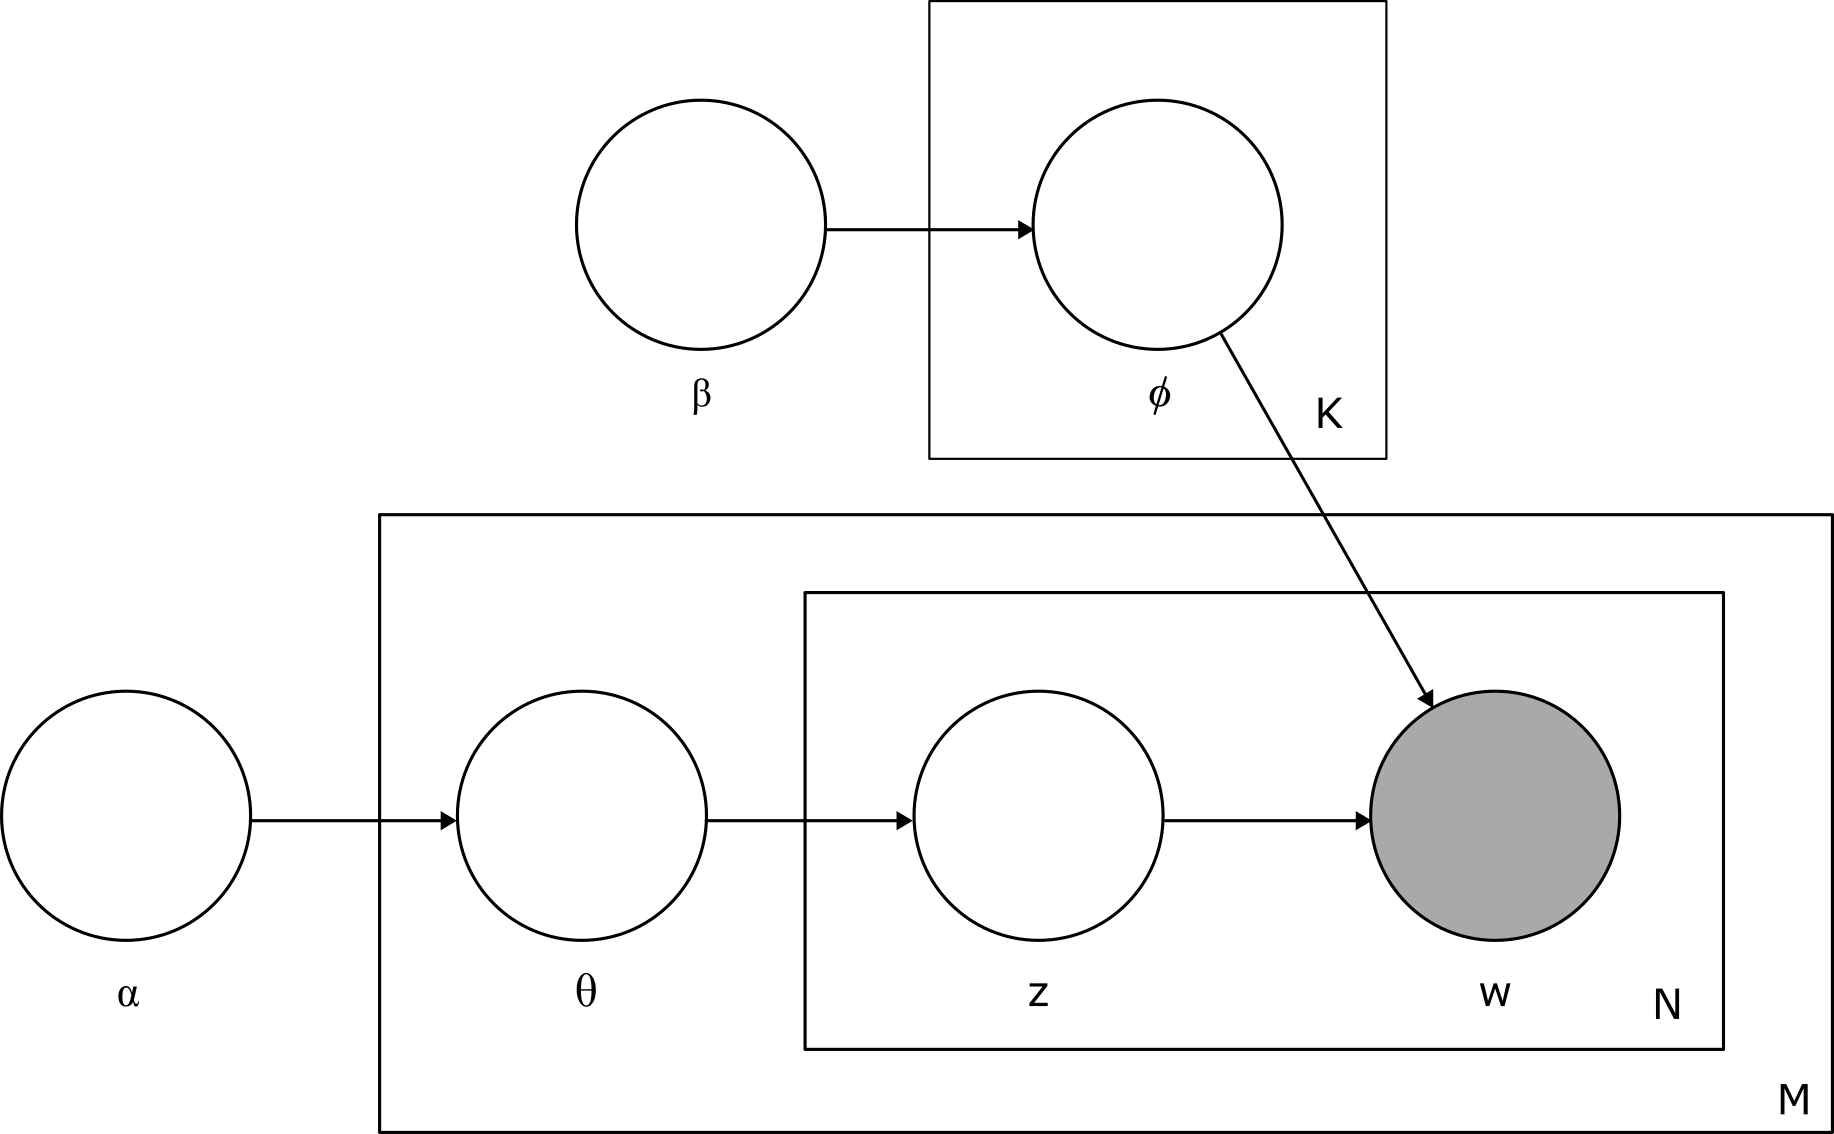
</center>
</div>

In LDA, the document index $d$ is not shown as a separate observable variable, and only words $w$ are shaded (observed). This is because LDA does not directly "observe" documents as entities. Instead, it models documents as mixtures of latent topics and assumes a generative process where: i) a document is generated by sampling a distribution over topics, ii) words in the document are generated from topics.

## Optimization: Gibbs sampling

Many algos for the optimization/training of the LDA are possible, and the original work also used an EM variant. We follow instead [this implementation](https://www.youtube.com/watch?v=4DsgCZ3KTNk), based on [this theoretical](https://coli-saar.github.io/cl19/materials/darling-lda.pdf) justification for Gibbs sampling.

In essence they find that given a set of words, each topic has the following probability:

$$
p(z_i|z^{(−i)}, \textbf{w}) \propto
(n^{(−i)}_{d,k} +\alpha_k)\frac{n^{(−i)}_{k,w} +\beta_w}{\sum_{w'}n^{(−i)}_{k,w'} +\beta_{w'}}
$$

The proportionality is usually used in probability to remove everything that does not depend on $i$ in this case, since it can be recovered through a normalizing factor which is simply the sum of all the $p(z_i|z^{(−i)}, \textbf{w})$ across $i$.


We will implement LDA from the tokenized documents, even if it can be coded from the count vector representation. Next cell defines a tokenization process, nothing you don't already excel at.

In [13]:
#@title spacy tokenization

import numpy as np
import spacy
import random
import pandas as pd
from tqdm import tqdm
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

# tokenizer
sp = spacy.load('en_core_web_sm')

# reproducibility
random.seed(42)
np.random.seed(42)

def generate_frequencies(data, max_docs=10_000):
    freqs = Counter()
    all_stopwords = sp.Defaults.stop_words
    all_stopwords.add('enron')
    nr_tokens = 0
    for doc in data[:max_docs]:
        tokens = sp.tokenizer(doc)
        for token in tokens:
            token_text = token.text.lower()
            if token_text not in all_stopwords and token.is_alpha:
                freqs[token_text] += 1
                nr_tokens += 1

    return freqs, nr_tokens


def get_vocab(freqs, freq_threshold=3):
    vocab = {}
    vocab_idx_str = {}
    vocab_idx = 0

    for word in freqs:
        if freqs[word] >= freq_threshold:
            vocab[word] = vocab_idx
            vocab_idx_str[vocab_idx] = word
            vocab_idx += 1

    return vocab, vocab_idx_str


def tokenize_dataset(data, vocab, max_docs=10_000):
    nr_tokens = 0
    nr_docs = 0
    docs = []

    for doc in data[:max_docs]:
        tokens = sp.tokenizer(doc)
        doc = []
        for token in tokens:
            token_text = token.text.lower()
            if token_text in vocab:
                doc.append(token_text)
                nr_tokens += 1
        docs.append(doc)
        nr_docs += 1

    print(f'Processed {nr_docs} documents with {nr_tokens} tokens')

    # Numericalize

    corpus = []
    for doc in docs:
        corpus_d = []
        for token in doc:
            corpus_d.append(vocab[token])

        corpus.append(np.asarray(corpus_d))

    return docs, corpus

## From scratch

In [14]:
ALPHA = 0.1
BETA = 0.1
N_TOPICS = 2

def LDA_Collapsed_Gibbs(corpus, vocab_size, num_iter=200):
    Z = []
    num_docs = len(corpus)

    for _, doc in enumerate(corpus):
        Zd = np.random.randint(0, N_TOPICS, len(doc))
        Z.append(Zd)

    ndk = np.zeros((num_docs, N_TOPICS))
    for d in range(num_docs):
        for k in range(N_TOPICS):
            ndk[d, k] = np.sum(Z[d] == k)

    nkw = np.zeros((N_TOPICS, vocab_size))
    for doc_idx, doc in enumerate(corpus):
        for word_idx, word in enumerate(doc):
            topic = Z[doc_idx][word_idx]
            nkw[topic, word] += 1

    nk = np.sum(nkw, axis=1)
    topic_list = list(range(N_TOPICS))

    # Gibbs sampling
    for _ in tqdm(range(num_iter)):
        for doc_idx, doc in enumerate(corpus):
            for i in range(len(doc)):
                word = doc[i]
                topic = Z[doc_idx][i]

                # remove z_i because conditioned on z_(-i)
                ndk[doc_idx, topic] -= 1
                nkw[topic, word] -= 1
                nk[topic] -= 1

                # EXERCISE: write the Gibbs probability for p(z_i|z^(-i),w)
                # assuming alpha and beta are vectors with a constant value
                # next line shows the mistake I made during the class
                # p_z = (ndk[doc_idx, :] + ALPHA)*(nkw.sum(axis=1) + BETA)/(nkw.sum(axis=1) + vocab_size*BETA)
                # the following line is the correct one
                p_z = (ndk[doc_idx, :] + ALPHA)*(nkw[:, word] + BETA)/(nkw.sum(axis=1) + vocab_size*BETA)
                topic = random.choices(topic_list, weights=p_z / np.sum(p_z), k=1)[0]

                # update n parameters
                Z[doc_idx][i] = topic
                ndk[doc_idx, topic] += 1
                nkw[topic, word] += 1
                nk[topic] += 1

    return Z, nkw, ndk

EXERCISE: where did the Dirichlet assumption end up in the code? check [here](https://coli-saar.github.io/cl19/materials/darling-lda.pdf), section 3.1.1!

In [15]:
documents = [
    "The cat sat on the mat.",
    "The dog barked at the mailman.",
    "Cats and dogs are friends.",
    "The mailman delivered the mail."
]

freqs, nr_tokens = generate_frequencies(documents)
vocab, vocab_idx_str = get_vocab(freqs, 0)
print('vocab:', vocab)
docs, corpus = tokenize_dataset(documents, vocab)
vocab_size = len(vocab)
print('vocab_size:', vocab_size)

vocab: {'cat': 0, 'sat': 1, 'mat': 2, 'dog': 3, 'barked': 4, 'mailman': 5, 'cats': 6, 'dogs': 7, 'friends': 8, 'delivered': 9, 'mail': 10}
Processed 4 documents with 12 tokens
vocab_size: 11


In [16]:
Z, nkw, ndk = LDA_Collapsed_Gibbs(corpus, vocab_size)

phi = nkw / np.sum(nkw, axis=1)[:, np.newaxis]

for topic_idx in range(N_TOPICS):
    print(f'Topic {topic_idx}')
    top_words = np.argsort(-phi[topic_idx, :])[:10]
    for word_idx in top_words:
        print(vocab_idx_str[word_idx], phi[topic_idx, word_idx])

100%|██████████| 200/200 [00:00<00:00, 3717.20it/s]

Topic 0
cat 0.16666666666666666
sat 0.16666666666666666
mat 0.16666666666666666
dogs 0.16666666666666666
cats 0.16666666666666666
friends 0.16666666666666666
mailman 0.0
dog 0.0
barked 0.0
delivered 0.0
Topic 1
mailman 0.3333333333333333
dog 0.16666666666666666
barked 0.16666666666666666
delivered 0.16666666666666666
mail 0.16666666666666666
sat 0.0
mat 0.0
cat 0.0
dogs 0.0
cats 0.0


## On sklearn

In [17]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer

n_topics = 2

# Sample document corpus
documents = [
    "The cat sat on the mat.",
    "The dog barked at the mailman.",
    "Cats and dogs are friends.",
    "The mailman delivered the mail."
]

# Use tf (raw term count) features for LDA.
print("Extracting tf features for LDA...")
tf_vectorizer = CountVectorizer(stop_words="english")
tf = tf_vectorizer.fit_transform(documents)

lda = LatentDirichletAllocation(
    n_components=n_topics,
    max_iter=100,
    learning_method="online",
    random_state=42,
)
t0 = time()
lda.fit(tf)

# Step 3: Extract topics
terms = vectorizer.get_feature_names_out()
topics = []
for i, component in enumerate(nmf.components_):  # Components are the topic-term matrices
    terms_in_topic = [(terms[idx], weight) for idx, weight in enumerate(component)]
    sorted_terms = sorted(terms_in_topic, key=lambda x: -x[1])[:10]  # Top 10 terms per topic
    topics.append(sorted_terms)

print("\nTopics:")
for i, topic in enumerate(topics):
    print(f"Topic {i + 1}:")
    for term, weight in topic:
        print(f"  {term}: {weight:.4f}")


Extracting tf features for LDA...

Topics:
Topic 1:
  barked: 0.9737
  dog: 0.9737
  mailman: 0.7677
  cat: 0.0000
  cats: 0.0000
  delivered: 0.0000
  dogs: 0.0000
  friends: 0.0000
  mail: 0.0000
  mat: 0.0000
Topic 2:
  mat: 0.9874
  sat: 0.9874
  cat: 0.9874
  barked: 0.0000
  cats: 0.0000
  delivered: 0.0000
  dog: 0.0000
  dogs: 0.0000
  friends: 0.0000
  mail: 0.0000
Topic 3:
  cats: 0.9874
  dogs: 0.9874
  friends: 0.9874
  barked: 0.0000
  cat: 0.0000
  delivered: 0.0000
  dog: 0.0000
  mail: 0.0000
  mailman: 0.0000
  mat: 0.0000
Topic 4:
  delivered: 1.1162
  mail: 1.1162
  mailman: 0.8800
  barked: 0.0000
  cat: 0.0000
  cats: 0.0000
  dog: 0.0000
  dogs: 0.0000
  friends: 0.0000
  mat: 0.0000


Notice that the difference in values between the scratch implementation and the sklearn function, is only a normalization factor.